# 20 - Multivariate Time Series Forecasting: when do other series help?
**Topic:** Time Series  |  **Reference:** "Multivariate Time Series Forecasting using Python" (amanxai.com, Mar 2024)

**Question.** If we forecast one series, does using the *other* series measured alongside it make the forecast better?

**Reference method:** four stock prices over about 3 months, differenced to make them stationary, a **Vector AutoRegression (VAR)** fitted and used to forecast; no comparison with anything simpler.
**What I do:** two experiments. **(A) The reference's own setting** (stocks) tested against a "no change" forecast, on its file and on 7 years of daily prices. **(B) A data set where multivariate information should matter:** hourly power-transformer data (ETTh1: 6 electrical load measurements and the oil temperature, 17,420 hours). I forecast the oil temperature 1, 6, 12 and 24 hours ahead with a seasonal-naive baseline, a VAR, and ridge regression / gradient boosting each fitted twice: **using only the oil temperature's own past (univariate)** and **using all 7 series (multivariate)**. The difference between the two fits is the value of the other series.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import grangercausalitytests
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMRegressor
from statsmodels.tools.sm_exceptions import ValueWarning, ConvergenceWarning
warnings.simplefilter("ignore", ValueWarning); warnings.simplefilter("ignore", ConvergenceWarning)
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)
st = pd.read_csv("../_data/stocks/stocks.csv", parse_dates=["Date"]); px = st.pivot(index="Date", columns="Ticker", values="Close").sort_index()
yf_ = pd.read_pickle("../_data/yf_stocks.pkl")["Close"].dropna()
et = pd.read_csv("../_data/etth1.csv", parse_dates=["date"]).set_index("date")
print("reference stocks file:", px.shape, px.index.min().date(), "to", px.index.max().date(), "| long stock history:", yf_.shape, yf_.index.min().date(), "to", yf_.index.max().date(), "| ETTh1:", et.shape, et.index.min(), "to", et.index.max())

reference stocks file: (62, 4) 2023-02-07 to 2023-05-05 | long stock history: (1760, 5) 2018-01-02 to 2024-12-30 | ETTh1: (17420, 7) 2016-07-01 00:00:00 to 2018-06-26 19:00:00


## 2. (A) The reference's setting: stock prices

**Look first.** Prices for AAPL, GOOG, MSFT and NFLX. Prices wander (non-stationary); day-to-day *changes* are what a model can try to predict. The test below holds out the last 10 trading days of the reference file and compares the VAR on first differences (order chosen by AIC, up to 5) with the **no-change forecast** (tomorrow's price = today's).

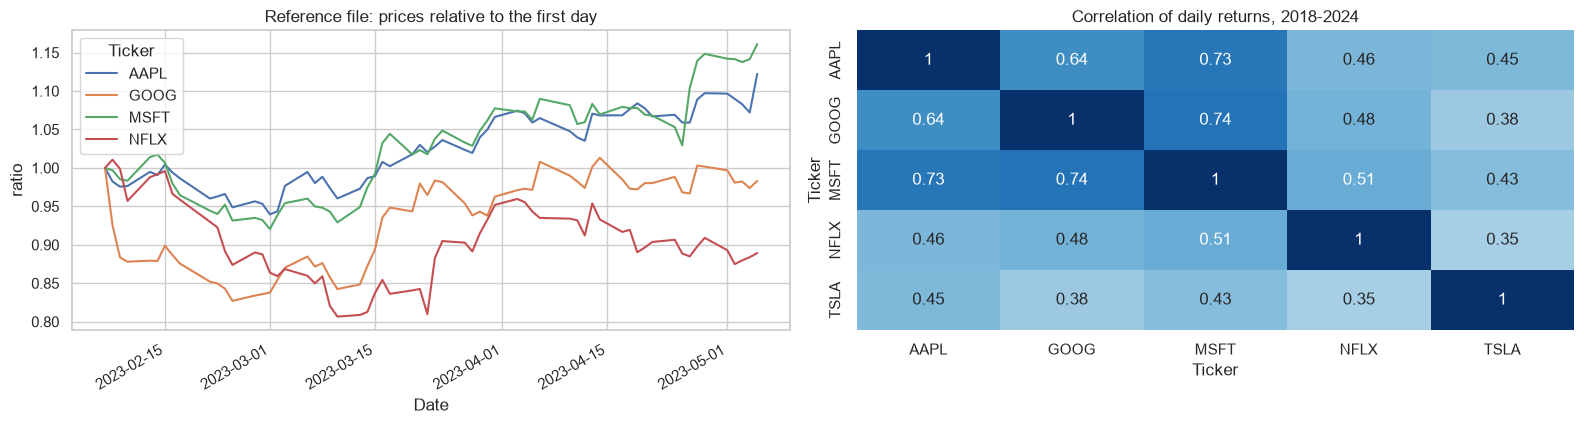

VAR order chosen by AIC: 0 | 10-day hold-out, RMSE of the daily price change in $:
      VAR RMSE of daily change  no-change RMSE
AAPL                      2.97            3.02
GOOG                      1.61            1.61
MSFT                      7.52            7.63
NFLX                      4.09            4.12
Granger-causality p-values (does t help predict AAPL's daily change?): {'MSFT': np.float64(0.33), 'GOOG': np.float64(0.832), 'NFLX': np.float64(0.702)}


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.4))
(px / px.iloc[0]).plot(ax=ax[0]); ax[0].set_title("Reference file: prices relative to the first day"); ax[0].set_ylabel("ratio")
sns.heatmap(yf_.pct_change().dropna().corr().round(2), annot=True, cmap="Blues", vmin=0, vmax=1, ax=ax[1], cbar=False); ax[1].set_title("Correlation of daily returns, 2018-2024")
plt.tight_layout(); plt.show()
d = px.diff().dropna(); train, test = d.iloc[:-10], d.iloc[-10:]
m = VAR(train.values).fit(maxlags=5, ic="aic"); fc = m.forecast(train.values[-m.k_ar:], 10) if m.k_ar > 0 else np.tile(np.asarray(m.intercept), (10, 1))      # order 0 = "only an average change"
rm = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
res = pd.DataFrame({t: {"VAR RMSE of daily change": rm(fc[:, i], test[t]), "no-change RMSE": rm(0 * test[t], test[t])} for i, t in enumerate(px.columns)}).T
print("VAR order chosen by AIC:", m.k_ar, "| 10-day hold-out, RMSE of the daily price change in $:"); print(res.round(2).to_string())
gc = {t: min(grangercausalitytests(d[[t, "AAPL"]].dropna() if t != "AAPL" else d[["MSFT", "AAPL"]], 1, verbose=False)[1][0]["ssr_ftest"][1], 1) for t in ["MSFT", "GOOG", "NFLX"]}
print("Granger-causality p-values (does t help predict AAPL's daily change?):", {k: round(v, 3) for k, v in gc.items()})

**Reading it.** On the reference's own file (62 days per stock) the Akaike criterion picks a VAR of **order 0**: the best "VAR" is just the average daily change, i.e. it finds no usable relationship between today's changes and tomorrow's. Its 10-day hold-out error is practically the same as the no-change forecast (AAPL 2.97 vs 3.02 dollars; GOOG 1.61 vs 1.61; MSFT 7.52 vs 7.63; NFLX 4.09 vs 4.12), and Granger-causality tests find no stock that helps predict Apple's daily change (p = 0.33, 0.83, 0.70). So the reference's multivariate model has nothing to add over "tomorrow = today" on this data; the article does not compare against that baseline.

**A longer test.** 2018-2024, 5 stocks. For each day in the last 3 years, a VAR(1) on daily returns refitted on the previous 3 years forecasts the next day's return; compare with predicting zero (and with predicting the training mean). R-squared against the "zero" forecast and the share of days where the sign is right.

In [3]:
ret = np.log(yf_).diff().dropna(); W = 750; rows = []
for i in range(len(ret) - 750, len(ret)):
    tr = ret.iloc[i - W:i]; mdl = VAR(tr.values).fit(1); f = mdl.forecast(tr.values[-1:], 1)[0]; rows.append((ret.index[i], f, ret.iloc[i].values, tr.mean().values))
F = np.array([r[1] for r in rows]); A = np.array([r[2] for r in rows]); M_ = np.array([r[3] for r in rows])
sse = lambda p: ((A - p) ** 2).sum(0); skill = 1 - sse(F) / sse(0 * F)
lg = pd.DataFrame({"R2 vs zero forecast (%)": skill * 100, "R2 of the training mean (%)": (1 - sse(M_) / sse(0 * F)) * 100, "sign correct (%)": (np.sign(F) == np.sign(A)).mean(0) * 100}, index=ret.columns); print("one-day-ahead return forecasts over %d days:" % len(rows)); print(lg.round(2).to_string())

one-day-ahead return forecasts over 750 days:
        R2 vs zero forecast (%)  R2 of the training mean (%)  sign correct (%)
Ticker                                                                        
AAPL                      -5.56                        -0.45             47.87
GOOG                      -2.90                        -0.22             48.67
MSFT                      -6.26                        -0.29             48.27
NFLX                      -1.83                        -0.14             49.60
TSLA                      -2.62                        -0.92             48.27


**Reading it.** Over 750 test days a VAR(1) refitted on a 3-year window predicts the next day's return **worse than predicting zero** for all five stocks (R-squared versus the zero forecast -1.8% to -6.3%), and gets the *sign* right on 47.9%-49.6% of days (a coin flip is 50%). Even the training average does not beat zero (-0.1% to -0.9%). Daily stock returns are close to unpredictable from their own and other stocks' past: multivariate models cannot add what is not there. This is the wrong place to look for a multivariate benefit.

## 3. (B) A real multivariate problem: hourly transformer data

**Look first.** Six load variables (HUFL/HULL: high-use-load, MUFL/MULL: medium, LUFL/LULL: low; each pair = useful and useless load) and the target **OT, the oil temperature**, hourly from July 2016 to June 2018. Split in time order, no shuffling: the first 12 months (8,640 hours, to 26 June 2017) for training, the next 4 months (2,880 hours) for validation (early stopping), and **everything after that, 5,900 hours from 24 October 2017 to 26 June 2018, for testing**.

       mean   std    min    max
HUFL   7.38  7.07 -22.71  23.64
HULL   2.24  2.04  -4.76  10.11
MUFL   4.30  6.83 -25.09  17.34
MULL   0.88  1.81  -5.93   7.75
LUFL   3.07  1.16  -1.19   8.50
LULL   0.86  0.60  -1.37   3.05
OT    13.32  8.57  -4.08  46.01


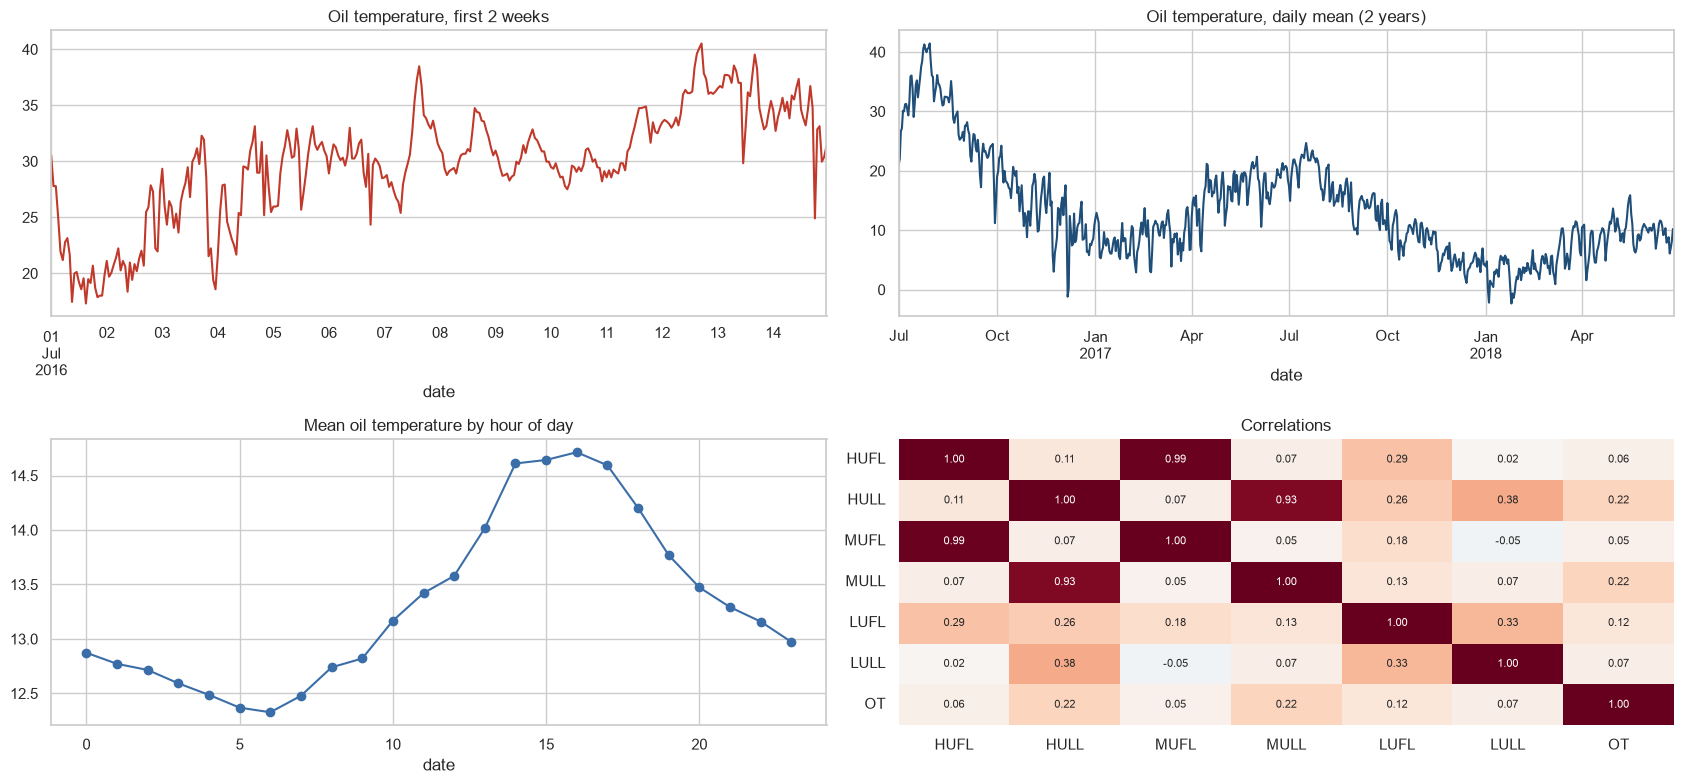

In [4]:
cols = list(et.columns); print(et.describe().round(2).T[["mean", "std", "min", "max"]].to_string())
fig, ax = plt.subplots(2, 2, figsize=(17, 8))
et.OT.iloc[:24 * 14].plot(ax=ax[0, 0], color="#c0392b"); ax[0, 0].set_title("Oil temperature, first 2 weeks")
et.OT.resample("D").mean().plot(ax=ax[0, 1], color="#1f4e79"); ax[0, 1].set_title("Oil temperature, daily mean (2 years)")
et.groupby(et.index.hour).OT.mean().plot(ax=ax[1, 0], marker="o", color="#3b6ea8"); ax[1, 0].set_title("Mean oil temperature by hour of day")
sns.heatmap(et.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1, 1], cbar=False, annot_kws={"size": 8}); ax[1, 1].set_title("Correlations")
plt.tight_layout(); plt.show()

**Reading it.** The oil temperature (OT, mean 13.3 degrees C, range -4 to 46) has a **yearly cycle** (about 25 in summer, 5-10 in winter), a **small daily cycle** (12.3 at 6:00 to 14.7 at 16:00, about 2.4 degrees) and a **big difference between the first summer and the second**: July 2016 averages about 35-40 degrees while July 2017 is about 20. The training year therefore contains temperatures the test period (October 2017 to June 2018) does not, and the series is not stationary. The correlations of OT with the six load variables are weak (0.05-0.22), so the *other series carry little linear information about OT*. The load variables HUFL/MUFL (0.99) and HULL/MULL (0.93) are almost copies of each other.

## 4. Setup: direct multi-horizon forecasting with lags
At every hour t, the inputs are the last 24 hours of the chosen series (**univariate**: oil temperature only; **multivariate**: all 7 series), plus hour-of-day and day-of-week as sine/cosine pairs; the target is the oil temperature at t+h for h in {1, 6, 12, 24}. One model per horizon. All series are standardised with training-set statistics. Evaluation: MAE in degrees over the 5,900 test hours; the same hourly origins for every method, except the VAR (every 6 hours, evaluated against the others on those same origins).

In [5]:
N_TR, N_VA = 12 * 30 * 24, 4 * 30 * 24; n = len(et); te0 = N_TR + N_VA
scaler = StandardScaler().fit(et.iloc[:N_TR]); Z = pd.DataFrame(scaler.transform(et), index=et.index, columns=cols)
L = 24; HZ = [1, 6, 12, 24]
def design(uni):
    use = ["OT"] if uni else cols; X = pd.concat({f"{c}_lag{k}": Z[c].shift(k) for c in use for k in range(L)}, axis=1)
    hr = et.index.hour.to_numpy(); dw = et.index.dayofweek.to_numpy()
    for nm, v, per in [("hour", hr, 24), ("dow", dw, 7)]:
        X[nm + "_sin"] = np.sin(2 * np.pi * v / per); X[nm + "_cos"] = np.cos(2 * np.pi * v / per)
    return X
Xu, Xm = design(True), design(False); sd_ot = scaler.scale_[cols.index("OT")]; mu_ot = scaler.mean_[cols.index("OT")]
def target(h): return Z.OT.shift(-h)
def fit_eval(X, h, kind, delta=False):
    y_true = target(h); y = y_true - Z.OT if delta else y_true; ok = X.notna().all(1) & y.notna(); idx = np.where(ok)[0]; tr = idx[idx < N_TR]; va = idx[(idx >= N_TR) & (idx < te0)]; te = idx[idx >= te0]
    if kind == "ridge": mdl = Ridge(alpha=10).fit(X.iloc[tr], y.iloc[tr])
    else: mdl = LGBMRegressor(n_estimators=400, learning_rate=.03, num_leaves=15, subsample=.8, subsample_freq=1, colsample_bytree=.7, min_child_samples=30, verbose=-1, random_state=0, n_jobs=8).fit(X.iloc[tr], y.iloc[tr], eval_set=[(X.iloc[va], y.iloc[va])], callbacks=[__import__("lightgbm").early_stopping(40, verbose=False)])
    pz = mdl.predict(X.iloc[te]) + (Z.OT.iloc[te].to_numpy() if delta else 0)
    return te, pz * sd_ot + mu_ot, y_true.iloc[te].to_numpy() * sd_ot + mu_ot, mdl
res, preds = {}, {}
for kind in ("ridge", "lightgbm"):
    for delta in (False, True):
        for uni, nm in ((True, "univariate"), (False, "multivariate")):
            lab = f"{kind} {nm}" + (" (predict change)" if delta else "")
            for h in HZ:
                te, p, a, mdl = fit_eval(Xu if uni else Xm, h, kind, delta); res[(lab, h)] = np.abs(p - a).mean(); preds[(lab, h)] = pd.Series(p, index=te)
                if kind == "lightgbm" and not uni and delta and h == 24: lgbm24 = mdl
actual = {h: pd.Series(a, index=te) for h in HZ for te, p, a, _ in [fit_eval(Xu, h, "ridge")]}

In [6]:
ot = et.OT
for h in HZ:
    tidx = actual[h].index
    res[("naive (last value)", h)] = np.abs(ot.iloc[list(tidx)].to_numpy() - actual[h].to_numpy()).mean()
    res[("seasonal naive (same hour yesterday)", h)] = np.abs(ot.iloc[[i + h - 24 for i in tidx]].to_numpy() - actual[h].to_numpy()).mean()
tab = pd.Series(res).unstack(); tab.columns = [f"MAE +{h}h" for h in tab.columns]; tab["mean"] = tab.mean(1)
print("test-period MAE of the oil temperature (degrees C), %d hours:" % (n - te0)); print(tab.sort_values("mean").round(2).to_string())

test-period MAE of the oil temperature (degrees C), 5900 hours:
                                        MAE +1h  MAE +6h  MAE +12h  MAE +24h  mean
lightgbm multivariate (predict change)     0.44     0.99      1.30      1.68  1.10
lightgbm univariate (predict change)       0.43     1.05      1.44      1.64  1.14
ridge univariate (predict change)          0.44     1.07      1.40      1.70  1.15
ridge univariate                           0.45     1.08      1.40      1.70  1.16
naive (last value)                         0.44     1.16      1.56      1.63  1.20
ridge multivariate (predict change)        0.47     1.18      1.58      1.89  1.28
ridge multivariate                         0.48     1.18      1.58      1.89  1.29
seasonal naive (same hour yesterday)       1.63     1.63      1.63      1.63  1.63
lightgbm univariate                        0.51     1.47      2.05      3.06  1.77
lightgbm multivariate                      0.57     1.95      2.73      3.82  2.27


**Reading it (test MAE in degrees C, mean over horizons +1, +6, +12, +24 hours).**
* **Predicting the level directly, the other series hurt:** ridge multivariate 1.29 vs univariate 1.16; LightGBM multivariate 2.27 vs univariate 1.77, much worse than simply repeating the last value (1.20) or yesterday's value at the same hour (1.63). Tree models cannot predict levels outside the range they saw in training and the series drifts between years.
* **Predicting the *change* from the current temperature repairs the trees**: LightGBM improves to 1.14 (univariate) and **1.10 (multivariate)**, the best entry. Ridge with the change target barely changes (the linear model already extrapolates).
* **The gain of the multivariate models over the naive last-value forecast is modest: about 8% on average (1.10 vs 1.20 degrees)**, and it appears at the medium horizons (+6h 0.99 vs 1.16 and +12h 1.30 vs 1.56) but not at +1 hour (0.44 for naive, 0.44 for the best) and +24 hours (1.68 vs 1.63: naive is better).
* One test period of 5,900 hours (24 October 2017 to 26 June 2018) and one seed: differences of a few hundredths of a degree (for example 1.10 vs 1.14) are within noise; I did not compute intervals.

## 5. VAR as in the reference, on the same task
VAR on all 7 standardised series fitted on the training period (order by AIC up to 24); forecast the next 24 hours from every 6th hour of the test period using the true past values (no refit).

In [7]:
tr_d = Z.iloc[:N_TR]; var = VAR(tr_d.values).fit(maxlags=24, ic="aic"); k = var.k_ar; origins = list(range(te0, n - 24, 6)); errs = {h: [] for h in HZ}
for o in origins:
    f = var.forecast(Z.iloc[o - k + 1:o + 1].values, 24)[:, cols.index("OT")] * sd_ot + mu_ot
    for h in HZ: errs[h].append(abs(f[h - 1] - ot.iloc[o + h]))
var_mae = {h: float(np.mean(errs[h])) for h in HZ}
cmp_ = {}
for nm in ["naive (last value)", "seasonal naive (same hour yesterday)", "ridge univariate", "ridge multivariate", "lightgbm univariate", "lightgbm multivariate", "ridge univariate (predict change)", "ridge multivariate (predict change)", "lightgbm univariate (predict change)", "lightgbm multivariate (predict change)"]:
    row = {}
    for h in HZ:
        if nm.startswith("naive"): p = ot.iloc[origins].to_numpy()
        elif nm.startswith("seasonal"): p = ot.iloc[[o + h - 24 for o in origins]].to_numpy()
        else: p = preds[(nm, h)].reindex([o + h for o in origins]).to_numpy() if False else preds[(nm, h)].reindex(origins).to_numpy()
        row[f"+{h}h"] = np.nanmean(np.abs(p - ot.iloc[[o + h for o in origins]].to_numpy()))
    cmp_[nm] = row
cmp_[f"VAR({k}) on 7 series"] = {f"+{h}h": var_mae[h] for h in HZ}
C2 = pd.DataFrame(cmp_).T; C2["mean"] = C2.mean(1); print("VAR order chosen by AIC:", k, "| same", len(origins), "origins for every method; MAE in degrees C:"); print(C2.sort_values("mean").round(2).to_string())

VAR order chosen by AIC: 24 | same 980 origins for every method; MAE in degrees C:
                                         +1h   +6h  +12h  +24h  mean
lightgbm multivariate (predict change)  0.46  0.97  1.29  1.64  1.09
lightgbm univariate (predict change)    0.46  1.06  1.42  1.61  1.14
ridge univariate (predict change)       0.46  1.05  1.40  1.67  1.15
ridge univariate                        0.47  1.05  1.40  1.68  1.15
naive (last value)                      0.47  1.13  1.52  1.61  1.18
ridge multivariate (predict change)     0.47  1.20  1.62  1.87  1.29
ridge multivariate                      0.48  1.20  1.62  1.88  1.29
VAR(24) on 7 series                     0.49  1.37  1.77  1.75  1.35
seasonal naive (same hour yesterday)    1.60  1.61  1.61  1.61  1.61
lightgbm univariate                     0.54  1.47  2.03  3.07  1.78
lightgbm multivariate                   0.61  1.94  2.73  3.84  2.28


**Reading it (the same 980 forecast origins for every method).** The VAR(24) of the reference's type, with an AIC-chosen order of 24, scores a mean MAE of **1.35**, worse than the last-value forecast (1.18) at 6 and 12 hours, and similar at 24. Gradient boosting on changes with all 7 series (1.09) is best again. A VAR is a linear model with 7 x 24 lagged terms per equation fitted on 12 months of data that do not resemble the test months; more parameters did not buy accuracy. The ranking agrees with the previous table.

## 6. How much do the other series add? And which ones?

reduction in MAE from adding the 6 other series (%), same learner:
                            +1h   +6h  +12h  +24h
ridge                      -7.6 -10.2 -13.4 -11.1
ridge (predict change)     -7.3  -9.9 -13.2 -11.0
lightgbm                  -13.2 -32.8 -33.2 -24.8
lightgbm (predict change)  -2.7   6.0   9.3  -2.3


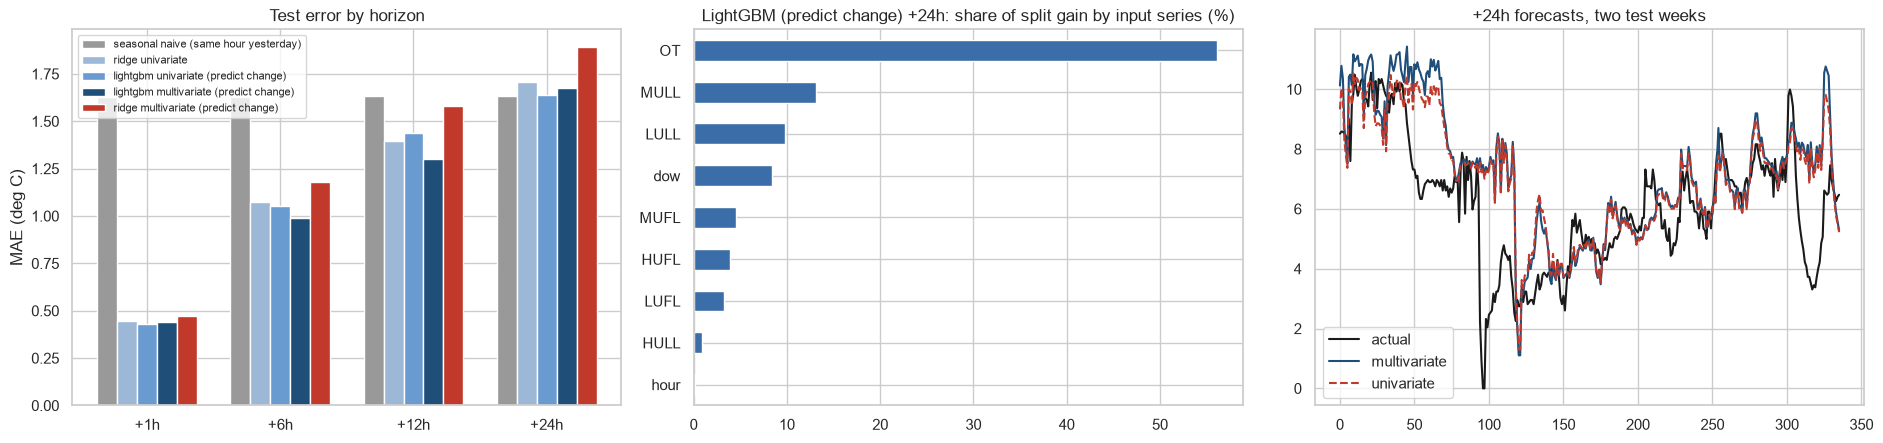

{'OT': 56.1, 'MULL': 13.1, 'LULL': 9.8, 'dow': 8.4, 'MUFL': 4.5, 'HUFL': 3.9, 'LUFL': 3.2, 'HULL': 0.9, 'hour': 0.2}


In [8]:
gain = pd.DataFrame({f"+{h}h": {f"{kind}{sfx}": (1 - tab.loc[f"{kind} multivariate{sfx}", f"MAE +{h}h"] / tab.loc[f"{kind} univariate{sfx}", f"MAE +{h}h"]) * 100 for kind in ("ridge", "lightgbm") for sfx in ("", " (predict change)")} for h in HZ}); print("reduction in MAE from adding the 6 other series (%), same learner:"); print(gain.round(1).to_string())
imp = pd.Series(lgbm24.booster_.feature_importance("gain"), index=Xm.columns); byvar = imp.groupby(lambda c: c.split("_lag")[0] if "_lag" in c else c.split("_")[0]).sum().sort_values(); byvar = byvar / byvar.sum() * 100
fig, ax = plt.subplots(1, 3, figsize=(19, 4.6))
x = np.arange(len(HZ)); w = .15
for j, (nm, c) in enumerate([("seasonal naive (same hour yesterday)", "#999"), ("ridge univariate", "#9db8d6"), ("lightgbm univariate (predict change)", "#6a9bd0"), ("lightgbm multivariate (predict change)", "#1f4e79"), ("ridge multivariate (predict change)", "#c0392b")]): ax[0].bar(x + (j - 2) * w, [tab.loc[nm, f"MAE +{h}h"] for h in HZ], w, label=nm, color=c)
ax[0].set_xticks(x); ax[0].set_xticklabels([f"+{h}h" for h in HZ]); ax[0].set_ylabel("MAE (deg C)"); ax[0].set_title("Test error by horizon"); ax[0].legend(fontsize=8)
byvar.plot.barh(ax=ax[1], color="#3b6ea8"); ax[1].set_title("LightGBM (predict change) +24h: share of split gain by input series (%)")
t = pd.concat([actual[24].rename("actual"), preds[("lightgbm multivariate (predict change)", 24)].rename("lightgbm multivariate"), preds[("lightgbm univariate (predict change)", 24)].rename("lightgbm univariate")], axis=1).iloc[24 * 20:24 * 34]
ax[2].plot(t.actual.values, "k", lw=1.5, label="actual"); ax[2].plot(t["lightgbm multivariate"].values, color="#1f4e79", label="multivariate"); ax[2].plot(t["lightgbm univariate"].values, color="#c0392b", ls="--", label="univariate"); ax[2].set_title("+24h forecasts, two test weeks"); ax[2].legend()
plt.tight_layout(); plt.show()
print({k: round(v, 1) for k, v in byvar.sort_values(ascending=False).items()})

**Reading it.**
* **The value of the other series depends on the model and target:** with a *linear* model they never help (ridge: -7% to -13%, i.e. error rises, because 168 highly correlated inputs add variance), with LightGBM predicting levels they hurt a lot (-13% to -33%), and with LightGBM predicting the *change* they help by 6% at +6h and 9% at +12h but not at +1h (-2.7%) or +24h (-2.3%).
* Which series? By split gain, the oil temperature's own lags carry 56% of the importance, then the medium and low useless loads **MULL (13%)** and **LULL (10%)**, the day of week (8%) and the rest below 5% each. The useless loads (MULL, LULL) matter more than the useful loads (MUFL, HUFL); this is a statement about what the model used and not a statement of cause.
* A more careful multivariate study would tune the regularisation of the linear model, use the equal-length training windows (the first year is unrepresentative) and repeat over several test periods.

## 7. Save

In [9]:
joblib.dump({"lgbm_24h_multivariate": lgbm24, "features": list(Xm.columns), "scaler": scaler, "cols": cols, "sd_ot": sd_ot, "mu_ot": mu_ot, "var": var}, "model/ett_forecasters.joblib")
json.dump({"test_mae": tab.round(3).to_dict("index"), "same_origins_mae": C2.round(3).to_dict("index"), "gain_pct": gain.round(2).to_dict("index"), "stocks_long": lg.round(3).to_dict("index")}, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['etth1_test_slice.csv.gz', 'ett_forecasters.joblib', 'meta.json']


## 8. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Data | 62 days of 4 stock prices | the same file, **plus** 7 years of stock returns **and** 17,420 hours of 7 power-transformer series (ETTh1) |
| Model | VAR on differenced prices | VAR, ridge and gradient boosting, univariate vs multivariate, level vs change target |
| Baseline | none | no-change, last value, same hour yesterday |
| Stocks | forecast shown | VAR order by AIC = 0; no better than "no change" (RMSE 2.97 vs 3.02 for AAPL); next-day returns R2 -2% to -6% vs zero, sign right 48-50% of days |
| Transformer | n/a | other series help only with the right setup: LightGBM predicting change, +6h and +12h (6-9% lower MAE); linear models and level targets get worse |
| Best result | n/a | LightGBM, 7 series, change target: mean MAE 1.10 vs 1.20 for "last value" (about 8% better) |

**What I learned.** (1) "Multivariate" is not automatically better; test the univariate version of the *same* learner. (2) Where the data have no predictable structure (daily stock returns) a VAR learns nothing (order 0). (3) For series that drift, predict the change, not the level, or tree models fail. (4) Always compare with last-value and seasonal-naive forecasts.

**Limits.** One test period; one seed; no hyper-parameter search for the linear models; ETTh1's training year is not like its test months; no intervals for the small differences. **Next step:** several rolling test periods, a tuned and regularised linear model, and a neural sequence model for completeness.